# RAG Assignment: Baseline Retrieval vs. Cross-Encoder Re-Ranking

**Document used:** *The Bharatiya Nyaya Sanhita, 2023* (BNS, Act No. 45 of 2023), the new Indian criminal code that replaced the IPC.
I used the official Gazette copy (102 pages, 358 sections) downloaded from the Ministry of Home Affairs website.

**Why I picked this document**

A legal code is a good stress test for dense retrieval because:
* many sections first give a general rule and then list *Exceptions* (for example murder vs. culpable homicide in Sec 101),
* a lot of clauses are written as negations, e.g. *"Nothing is an offence which..."*, *"There is no right of private defence..."*,
* some rules apply only to particular roles (public servant, child, spouse),
* similar words (theft, stolen, property, punishment) appear in dozens of sections, so there are many lexical distractors.

**Tools / models**

| Component | Model / Tool |
|---|---|
| PDF parsing | `pypdf` |
| Bi-Encoder (dense embeddings) | `sentence-transformers/all-MiniLM-L6-v2` |
| Vector store | `FAISS` `IndexFlatIP` (inner product on L2-normalised vectors = cosine similarity) |
| Cross-Encoder (re-ranker) | `cross-encoder/ms-marco-MiniLM-L-6-v2` |
| LLM | `openai/gpt-oss-120b` (open-weights model) through the **Groq API** |


**Outline of the notebook**
1. Setup and configuration
2. Loading and cleaning the PDF
3. Chunking (one chunk list shared by both pipelines)
4. Pipeline 1: Baseline (Bi-Encoder, Top 10, Top 3 to LLM, **Answer 1**)
5. Pipeline 2: Re-Ranking (same Top 10, Cross-Encoder, Top 3 to LLM, **Answer 2**)
6. Failure mode analysis (stress tests), rank shifts, metrics and answer comparison
7. Latency profiling
8. Scaling experiment (why the cross-encoder is not run on the whole corpus)
9. Summary of observations

## 1. Setup and Configuration

In [1]:
# Run once on a new machine (uncomment):
# !pip install -r requirements.txt
#
# The LLM is called through the Groq API (https://console.groq.com, free tier).
# Put the key in a file called .env in this folder (.env is listed in .gitignore, so it is never pushed):
#   GROQ_API_KEY=gsk_xxxxxxxx
#
# Note: I first tried Llama-3 8B locally through Ollama, but on my 8 GB laptop the LLM together with the
# two encoders used up all the RAM and the machine froze, so I moved only the generation step to an API.
# The retrieval part (bi-encoder, FAISS, cross-encoder) still runs locally.

In [ ]:
import os

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"

import re, time, json, hashlib, warnings
import numpy as np
import pandas as pd
import requests
import faiss
import pypdf
import torch
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer, CrossEncoder

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
torch.set_num_threads(1)   # keep PyTorch single threaded as well (same OpenMP issue as above)

# ---------------- Configuration ----------------
PDF_PATH       = "data/Bharatiya_Nyaya_Sanhita_2023.pdf"
BI_ENCODER     = "sentence-transformers/all-MiniLM-L6-v2"   # Bi-Encoder used for indexing + retrieval
CROSS_ENCODER  = "cross-encoder/ms-marco-MiniLM-L-6-v2"     # Cross-Encoder used for re-ranking
LLM_URL        = "https://api.groq.com/openai/v1/chat/completions"
LLM_MODEL      = "openai/gpt-oss-120b"
LLM_CACHE_PATH = "llm_cache.json"   # saved LLM answers, so the notebook gives the same answers when re-run
DEVICE         = "cpu"   # both encoders run locally on the CPU

CHUNK_WORDS    = 150     # words per chunk
OVERLAP_WORDS  = 30      # overlap between two neighbouring chunks
TOP_K_RETRIEVE = 10      # candidates returned by the bi-encoder (step b of both pipelines)
TOP_K_CONTEXT  = 3       # chunks that are finally put into the LLM prompt

os.makedirs("figures", exist_ok=True)   # charts are also saved here for the report
BLUE, ORANGE = "#2a78d6", "#eb6834"    # Pipeline 1 = blue, Pipeline 2 = orange in every chart

def load_api_key(path=".env"):
    """Read the Groq key from the environment or from the .env file, so the key is never written in the notebook."""
    if os.environ.get("GROQ_API_KEY"):
        return os.environ["GROQ_API_KEY"]
    with open(path) as f:
        for line in f:
            m = re.match(r"\s*GRO[QK]_API_KEY\s*=\s*[\"']?([^\"'\s]+)", line)
            if m:
                return m.group(1)
    raise RuntimeError("GROQ_API_KEY not found in .env")

API_KEY = load_api_key()

## 2. Load and Clean the PDF

When I first used plain `extract_text()`, the output had three kinds of noise:
1. **Margin notes**: the section titles printed in the side column (left side on even pages, right side on odd pages). They got mixed into the middle of the body text.
2. **Running header**: `THE GAZETTE OF INDIA EXTRAORDINARY ...` on every page.
3. **Masthead and signature block**: the Hindi masthead (legacy font, comes out as junk characters) on page 1 and the publisher / digital signature footer on the last page.

To drop the margin notes I used the `visitor_text` callback of `pypdf`. It gives the x/y position of every piece of text, so I only keep the pieces that lie inside the main body column. The x limits were found by printing positions for a few pages.

In [ ]:
reader = pypdf.PdfReader(PDF_PATH)
print("Pages in PDF:", len(reader.pages))

# Body text lies roughly between x=245 and x=900 (pypdf units).
# Margin notes are at x~120 (even pages) or x~1010 (odd pages), so anything outside 200-980 is dropped.
MARGIN_LEFT, MARGIN_RIGHT = 200, 980

def extract_body_text(page):
    """Return only the body-column text of one page. Lines are rebuilt using the y coordinate."""
    lines, current, last_y = [], [], None

    def visitor(text, cm, tm, font_dict, font_size):
        nonlocal current, last_y
        if not text.strip():                       # whitespace: keep it only inside a line
            if text and current:
                current.append(text)
            return
        x = tm[4] * cm[0] + cm[4]
        y = tm[5] * cm[3] + cm[5]
        if x < MARGIN_LEFT or x > MARGIN_RIGHT:    # margin note -> skip
            return
        if last_y is not None and abs(y - last_y) > 3:   # y changed, so a new line has started
            lines.append("".join(current)); current = []
        current.append(text); last_y = y

    page.extract_text(visitor_text=visitor)
    lines.append("".join(current))
    return "\n".join(l.strip() for l in lines)

# Text that only appears in the footer / signature block on the last page
FOOTER_MARKERS = ("DIW AKAR SINGH", "Joint Secretary", "UPLOADED BY", "MGIPMRND",
                  "PUBLISHED BY THE CONTROLLER")

def clean_page(text, page_no):
    """Remove the running header, the Hindi masthead (page 1) and the signature block (last page)."""
    if page_no == 1 and "vlk/kkj" in text:       # start of the Hindi masthead in the legacy font
        text = text[:text.index("vlk/kkj")]
    kept = []
    for line in text.split("\n"):
        s = line.strip()
        if not s or "GAZETTE OF INDIA" in s or re.fullmatch(r"[_\s]+", s):
            continue
        if s.startswith("— —") or any(m in s for m in FOOTER_MARKERS):
            break                                   # the Act's text ends here
        kept.append(s)
    return "\n".join(kept)

pages = [clean_page(extract_body_text(p), i + 1) for i, p in enumerate(reader.pages)]
print("Total words after cleaning:", sum(len(p.split()) for p in pages))
print("\n--- Sample (page 12) ---\n", pages[11][:700])

Pages in PDF: 102


Total words after cleaning: 60472

--- Sample (page 12) ---
 20.Nothing is an offence which is done by a child under seven years of age.
21.Nothing is an offence which is done by a child above seven years of age and under
twelve years of age, who has not attained sufficient maturity of understanding to judge of
the nature and consequences of his conduct on that occasion.
22.Nothing is an offence which is done by a person who, at the time of doing it, by
reason of unsoundness of mind, is incapable of knowing the nature of the act, or that he is
doing what is either wrong or contrary to law.
23. Nothing is an offence which is done by a person who, at the time of doing it, is, by
reason of intoxication, incapable of knowing the nature of the act, or that


## 3. Chunking

I used a **fixed-size sliding window of 150 words with 30 words overlap**.
* 150 words is roughly 200 word-pieces, which is under the 256 token limit of MiniLM, so the bi-encoder sees the full chunk and nothing gets cut off.
* The overlap lowers the chance that a short clause like an *Exception* is split between two chunks.

For every chunk I also store the page number and the BNS section number(s) it covers (a section starts on a line like `"101."`). This is only used to label the results so I can check them against the Act; it is not given to the retriever.

**Both pipelines use exactly this list of chunks and the same index.**

In [4]:
# Step 1: flatten the whole document into a list of words, and remember the page and section of each word.
words, section = [], 0
for page_no, text in enumerate(pages, start=1):
    for line in text.split("\n"):
        # a new section starts with "<n>." followed by text, e.g. "101.Except in the cases..."
        m = re.match(r"^(\d{1,3})\.\s?(\(1\))?\s?[A-Z“(]", line)
        # sections come in increasing order, so this check ignores numbered items inside a section
        if m and section < int(m.group(1)) <= section + 2:
            section = int(m.group(1))
        for w in line.split():
            words.append((w, page_no, section))

# Step 2: slide a window of CHUNK_WORDS over the words, moving by (CHUNK_WORDS - OVERLAP_WORDS) each time.
chunks = []
step = CHUNK_WORDS - OVERLAP_WORDS
for start in range(0, len(words), step):
    seg = words[start:start + CHUNK_WORDS]
    first, last = seg[0][2], seg[-1][2]
    chunks.append({
        "chunk_id": len(chunks),
        "page": seg[0][1],
        "section": f"Sec {first}" if first == last else f"Sec {first}-{last}",
        "text": " ".join(w for w, _, _ in seg),
    })
    if start + CHUNK_WORDS >= len(words):
        break

print(f"Sections detected: {section} | Chunks created: {len(chunks)}")
pd.DataFrame(chunks)[["chunk_id", "page", "section", "text"]].head(3)

Sections detected: 358 | Chunks created: 504


,chunk_id,page,section,text
0,0,1,Sec 0-1,"THE BHARA TIY A NY A Y A SANHITA, 2023 NO. 45 OF 2023 [25th December ,2023.] An Act to consolidate and amend the pro..."
1,1,2,Sec 1,"contrary to the provisions thereof, of which he shall be guilty within India. (4) Any person liable, by any law for ..."
2,2,2,Sec 1-2,"targeting a computer resource located in India. Explanation.—In this section, the word “offence” includes every act ..."


## 4. Pipeline 1: Baseline Retrieval (Bi-Encoder)

**a. Indexing.** Each chunk is encoded *on its own* by the bi-encoder into a 384-dimensional vector. The vectors are L2-normalised, so the inner product computed by `IndexFlatIP` is the same as cosine similarity. This is done once, offline.

**b. Retrieval.** The query is encoded with the same model and FAISS returns the **Top 10** most similar chunks.

**c. Generation.** The first **3** of these 10 chunks go into the LLM prompt, which gives **Answer 1**.

In [5]:
def realign_weights(model):
    # Fix for macOS (Accelerate): the weights loaded from .safetensors can sit at a badly aligned
    # memory address and CPU matrix multiplication then gives NaN. Copying each tensor into new memory
    # fixes it. The weight values do not change.
    for p in model.parameters():
        p.data = p.data.clone()
    return model

bi_encoder = realign_weights(SentenceTransformer(BI_ENCODER, device=DEVICE))

# (a) Index all chunks once
t0 = time.perf_counter()
chunk_embeddings = bi_encoder.encode([c["text"] for c in chunks], batch_size=64,
                                     normalize_embeddings=True, show_progress_bar=False).astype("float32")
index = faiss.IndexFlatIP(chunk_embeddings.shape[1])   # exact (brute force) inner-product search
index.add(chunk_embeddings)
INDEXING_TIME = time.perf_counter() - t0
print(f"Indexed {index.ntotal} chunks, dim = {chunk_embeddings.shape[1]}, one-time indexing cost = {INDEXING_TIME:.2f} s")

Indexed 504 chunks, dim = 384, one-time indexing cost = 12.93 s


In [6]:
def baseline_retrieve(query, k=TOP_K_RETRIEVE):
    """(b) Bi-encoder retrieval. Returns a list of (chunk_id, cosine_score) for the top-k chunks."""
    q = bi_encoder.encode([query], normalize_embeddings=True).astype("float32")
    scores, ids = index.search(q, k)
    return [(int(i), float(s)) for i, s in zip(ids[0], scores[0])]

# quick check
baseline_retrieve("What is the punishment for theft?")[:3]

[(388, 0.7102477550506592),
 (386, 0.6823506355285645),
 (394, 0.6820189356803894)]

## 5. Pipeline 2: Re-Ranking (Cross-Encoder)

**a.** Take the same **Top 10** candidates that the baseline returned.
**b.** Give each *(query, chunk)* pair **together** to the cross-encoder. It reads both texts in one input and outputs one relevance score.
**c.** Sort the 10 candidates by this score (highest first) and keep the **Top 3**.
**d.** Send these 3 chunks to the LLM with the **same prompt** as Pipeline 1, which gives **Answer 2**.

In [7]:
cross_encoder = CrossEncoder(CROSS_ENCODER, device=DEVICE)
realign_weights(cross_encoder.model)
assert np.isfinite(cross_encoder.predict([("test", "test passage")])).all(), "cross-encoder returned NaN"

def rerank(query, candidates):
    """(b)+(c) Score every (query, chunk) pair with the cross-encoder and sort by that score.
    Returns a list of (chunk_id, ce_score, original_rank) in descending order of ce_score."""
    pairs = [(query, chunks[cid]["text"]) for cid, _ in candidates]
    ce_scores = cross_encoder.predict(pairs)
    rescored = [(cid, float(s), rank + 1) for rank, ((cid, _), s) in enumerate(zip(candidates, ce_scores))]
    return sorted(rescored, key=lambda x: x[1], reverse=True)

### Shared LLM prompt

Both pipelines call the same `ask_llm()` function with the same model and the same template; only the 3 context chunks are different.
Temperature is 0 and the seed is fixed, so any difference between Answer 1 and Answer 2 comes from the retrieved context and not from random sampling.

In [8]:
PROMPT_TEMPLATE = """You are a legal assistant answering questions about the Bharatiya Nyaya Sanhita, 2023 (BNS).
Answer the question using ONLY the context passages below. Mention the section number(s) you rely on.
If the context does not contain the answer, reply exactly: "The provided context does not contain this information."

Context:
{context}

Question: {question}
Answer (2-4 sentences):"""

def build_context(chunk_ids):
    # each passage is labelled with its section and page so the LLM can cite it
    return "\n\n".join(f"[Passage {n} | {chunks[c]['section']}, page {chunks[c]['page']}]\n{chunks[c]['text']}"
                       for n, c in enumerate(chunk_ids, start=1))

# Cache of LLM answers. Even at temperature 0 an API model can give slightly different wording on
# another run, and my written analysis refers to the exact answers. So every answer is saved together
# with the time the API call took, keyed by a hash of (model + full prompt). Delete llm_cache.json to
# call the API again from scratch.
llm_cache = json.load(open(LLM_CACHE_PATH)) if os.path.exists(LLM_CACHE_PATH) else {}

def ask_llm(question, chunk_ids, max_tries=6):
    """Send the prompt to the LLM through the Groq API. Returns (answer, seconds taken by the call).
    The free tier allows only about 8000 tokens per minute, so on a 429 (rate limit) error I wait and
    try again. The waiting time is not counted in the returned latency."""
    prompt = PROMPT_TEMPLATE.format(context=build_context(chunk_ids), question=question)
    key = hashlib.sha256((LLM_MODEL + prompt).encode()).hexdigest()
    if key in llm_cache:
        return llm_cache[key]["answer"], llm_cache[key]["seconds"]
    body = {"model": LLM_MODEL, "messages": [{"role": "user", "content": prompt}],
            "temperature": 0, "seed": 42,
            "reasoning_effort": "low"}   # gpt-oss is a reasoning model; "low" keeps it short and fast
    for attempt in range(max_tries):
        t0 = time.perf_counter()
        r = requests.post(LLM_URL, headers={"Authorization": f"Bearer {API_KEY}"}, json=body, timeout=120)
        elapsed = time.perf_counter() - t0
        if r.status_code == 429:                       # rate limit -> wait, then retry
            time.sleep(float(r.headers.get("retry-after", 10)) + 1)
            continue
        r.raise_for_status()
        answer = r.json()["choices"][0]["message"]["content"].strip()
        if not answer:
            raise RuntimeError(f"Empty LLM response: {r.json()}")
        llm_cache[key] = {"answer": answer, "seconds": elapsed}
        json.dump(llm_cache, open(LLM_CACHE_PATH, "w"), indent=1)
        return answer, elapsed
    raise RuntimeError("LLM API is still rate limited after several retries")

# check that the API key works before running the experiments
print(ask_llm("What is the short title of this Act?", [0])[0])

The short title of the Act is provided in Section 1(1): “This Act may be called the **Bharatiya Nyaya Sanhita, 2023**.”【Passage 1 | Sec 0‑1, page 1】


### The two pipelines as functions

`pipeline_1` and `pipeline_2` follow steps a-c and a-d from the assignment exactly. Pipeline 2 receives the Top 10 list produced by Pipeline 1, so both work on the same candidates. Each stage is timed separately.

In [9]:
def pipeline_1(query):
    """Baseline: bi-encoder Top 10 -> first 3 chunks -> LLM -> Answer 1."""
    t0 = time.perf_counter()
    top10 = baseline_retrieve(query)                          # (b) Top 10 by cosine similarity
    t_retrieve = time.perf_counter() - t0
    context_ids = [cid for cid, _ in top10[:TOP_K_CONTEXT]]   # (c) Top 3 directly
    answer, t_llm = ask_llm(query, context_ids)
    return {"top10": top10, "context": context_ids, "answer": answer,
            "t_retrieve": t_retrieve, "t_llm": t_llm}

def pipeline_2(query, top10):
    """Re-ranking: same Top 10 -> cross-encoder -> re-sorted Top 3 -> LLM (same prompt) -> Answer 2."""
    t0 = time.perf_counter()
    reranked = rerank(query, top10)                              # (b) + (c)
    t_rerank = time.perf_counter() - t0
    context_ids = [cid for cid, _, _ in reranked[:TOP_K_CONTEXT]]
    answer, t_llm = ask_llm(query, context_ids)                  # (d)
    return {"reranked": reranked, "context": context_ids, "answer": answer,
            "t_rerank": t_rerank, "t_llm": t_llm}

### Helper for the experiments

To measure rank shifts I need to know which chunk *should* be retrieved. For every test query I picked a short phrase copied word-for-word from the governing clause of the Act. The chunk(s) containing that phrase are marked as the **gold chunk**. `run_both()` then:
* runs Pipeline 1 and Pipeline 2,
* prints the two rankings side by side (gold chunk marked with `<== GOLD`),
* prints the rank of the gold chunk before and after re-ranking,
* prints Answer 1 and Answer 2.

In [10]:
def norm(s):
    return re.sub(r"\s+", " ", s).lower()

def find_gold(phrase):
    """Ids of all chunks whose text contains the phrase (ignores case and extra spaces)."""
    return {c["chunk_id"] for c in chunks if norm(phrase) in norm(c["text"])}

def show_chunk(cid):
    print(f"--- Chunk {cid} | {chunks[cid]['section']} | page {chunks[cid]['page']} ---\n{chunks[cid]['text']}\n")

def label(cid, gold):
    return f"{cid} ({chunks[cid]['section']})" + ("  <== GOLD" if cid in gold else "")

def run_both(query, gold_phrase, category):
    gold = find_gold(gold_phrase)
    assert gold, "gold phrase not found in any chunk"

    p1 = pipeline_1(query)
    p2 = pipeline_2(query, p1["top10"])
    base, rr = p1["top10"], p2["reranked"]

    # side-by-side table of the two rankings
    rows = []
    for pos in range(TOP_K_RETRIEVE):
        b_cid, b_s = base[pos]
        r_cid, r_s, r_from = rr[pos]
        rows.append({"rank": pos + 1,
                     "baseline chunk": label(b_cid, gold), "cosine": round(b_s, 3),
                     "re-ranked chunk": label(r_cid, gold), "CE score": round(r_s, 2),
                     "was rank": r_from})
    table = pd.DataFrame(rows).set_index("rank")

    # rank of the (best placed) gold chunk in each list
    b_rank = next((i + 1 for i, (c, _) in enumerate(base) if c in gold), None)
    r_rank = next((i + 1 for i, (c, _, _) in enumerate(rr) if c in gold), None)
    gold_cid = next((c for c, _ in base if c in gold), None)

    result = {"category": category, "query": query, "gold_chunk": gold_cid,
              "gold_section": chunks[gold_cid]["section"] if gold_cid is not None else None,
              "baseline_rank": b_rank, "reranked_rank": r_rank,
              "in_top3_baseline": b_rank is not None and b_rank <= TOP_K_CONTEXT,
              "in_top3_reranked": r_rank is not None and r_rank <= TOP_K_CONTEXT,
              "answer1": p1["answer"], "answer2": p2["answer"],
              "t_retrieve": p1["t_retrieve"], "t_rerank": p2["t_rerank"],
              "t_llm1": p1["t_llm"], "t_llm2": p2["t_llm"]}

    # which chunks entered / left the Top 3 because of re-ranking
    base_rank_of = {c: i + 1 for i, (c, _) in enumerate(base)}
    rr_rank_of = {c: i + 1 for i, (c, _, _) in enumerate(rr)}
    entered = [c for c in p2["context"] if c not in p1["context"]]
    left = [c for c in p1["context"] if c not in p2["context"]]
    result["moved_into_top3"] = [f"{c}: #{base_rank_of[c]} -> #{rr_rank_of[c]}" for c in entered]
    result["dropped_from_top3"] = [f"{c}: #{base_rank_of[c]} -> #{rr_rank_of[c]}" for c in left]

    print(f"QUERY: {query}")
    print(f"Gold chunk {gold_cid} ({result['gold_section']}) moved from Rank #{b_rank} -> Rank #{r_rank}")
    print(f"Moved into the Top 3 : {result['moved_into_top3']}")
    print(f"Dropped from Top 3   : {result['dropped_from_top3']}")
    display(table)
    print(f"ANSWER 1 (Baseline, context chunks {p1['context']}):\n{p1['answer']}\n")
    print(f"ANSWER 2 (Re-ranked, context chunks {p2['context']}):\n{p2['answer']}")
    return result

results = []

## 6. Failure Mode Analysis (Stress Testing)

For each test I first print the **gold chunk** (the clause that actually answers the question), so that Answer 1 and Answer 2 can be checked against the real text of the Act. The queries are written the way a normal person would ask them, not in legal language, because that is where the bi-encoder has the most trouble.

| # | Failure type | What the query tests |
|---|---|---|
| 6.1 | Keyword trap / distractor | "stolen phone" matches the theft illustrations, but the answer is in Sec 317 (receiving stolen property) |
| 6.2 | Exception / corner case | general definition of murder vs. *Exception 4* (sudden fight) in Sec 101 |
| 6.3 | Negation and constraints | "Except murder..." restriction on the defence of threats (Sec 32) and "There is no right of private defence" against a public servant (Sec 37) |
| 6.4 | Other document-specific failures | general exceptions written in abstract legal language (necessity Sec 19, consent Sec 25) |
| 6.5 | Limits of re-ranking | cases where the cross-encoder does not help or makes things worse |

### 6.1 Keyword Trap / Distractor

The query has the words *stolen* and *phone/property*, which overlap strongly with the long list of theft illustrations under Sec 303 (*"A takes Z's ring..."*, *"A delivers his watch..."*). But buying something is not theft. The actual rule is **Sec 317(2)**, which uses different words: *"dishonestly receives or retains any stolen property, **knowing or having reason to believe** the same to be stolen"*. So the important point (knowledge is required) is in a chunk that does not look similar on the surface.

**Query:** *Is it a crime to buy a stolen mobile phone if I did not know it was stolen?*

In [11]:
gold_phrase = "knowing or having reason to believe the same to be stolen property"
for cid in sorted(find_gold(gold_phrase)):
    show_chunk(cid)

--- Chunk 417 | Sec 317 | page 85 ---
in respect of which criminal breach of trust has been committed, is designated as stolen property, whether the transfer has been made, or the misappropriation or breach of trust has been committed, within or without India, but, if such property subsequently comes into the possession of a person legally entitled to the possession thereof, it then ceases to be stolen property. (2) Whoever dishonestly receives or retains any stolen property, knowing or having reason to believe the same to be stolen property, shall be punished with imprisonment of either description for a term which may extend to three years, or with fine, or with both. (3) Whoever dishonestly receives or retains any stolen property, the possession whereof he knows or has reason to believe to have been transferred by the commission of dacoity, or dishonestly receives from a person, whom he knows or has reason to believe to belong or



In [12]:
results.append(run_both("Is it a crime to buy a stolen mobile phone if I did not know it was stolen?",
                        gold_phrase, "Keyword trap"))

QUERY: Is it a crime to buy a stolen mobile phone if I did not know it was stolen?
Gold chunk 417 (Sec 317) moved from Rank #6 -> Rank #1
Moved into the Top 3 : ['417: #6 -> #1']
Dropped from Top 3   : ['408: #3 -> #6']


,baseline chunk,cosine,re-ranked chunk,CE score,was rank
rank,,,,,
1,381 (Sec 303),0.408,417 (Sec 317) <== GOLD,-5.69,6
2,380 (Sec 303),0.389,380 (Sec 303),-6.31,2
3,408 (Sec 314-315),0.354,381 (Sec 303),-6.63,1
4,386 (Sec 303-305),0.343,386 (Sec 303-305),-6.81,4
5,383 (Sec 303),0.335,377 (Sec 302-303),-7.48,7
6,417 (Sec 317) <== GOLD,0.317,408 (Sec 314-315),-8.14,3
7,377 (Sec 302-303),0.310,383 (Sec 303),-8.80,5
8,394 (Sec 308-309),0.307,402 (Sec 313-314),-9.02,10
9,388 (Sec 306-307),0.303,388 (Sec 306-307),-9.19,9


ANSWER 1 (Baseline, context chunks [381, 380, 408]):
The provided context does not contain this information.

ANSWER 2 (Re-ranked, context chunks [417, 380, 381]):
Section 317(2) of the Bharatiya Nyaya Sanhita, 2023 provides that a person is punishable for “dishonestly receiving or retaining any stolen property, **knowing or having reason to believe** the same to be stolen.” Because the offence requires knowledge (or reason to believe) that the property is stolen, buying a mobile phone without such knowledge does not constitute a crime under this provision.


**Observation.** The bi-encoder fills the top 5 with Sec 303 theft illustrations because they share the words *stolen*, *watch*, *ring*, *property*. The real rule (Sec 317) is only at rank 6. With that context the LLM correctly refuses (*"context does not contain this information"*), so Answer 1 is useless to the user. After re-ranking Sec 317 is at rank 1 and Answer 2 gives the key condition: the offence needs *"knowing or having reason to believe"* the phone was stolen.

### 6.2 Exception / Corner Case

Sec 101 first defines murder and then lists *Exceptions 1-5*, where culpable homicide is **not** murder. My query describes Exception 4 (sudden fight in the heat of passion) in simple words. The bi-encoder prefers the chunks with the general definition of murder / culpable homicide, and the exception is in a separate chunk lower down.

**Query:** *Is it murder if two people get into a sudden quarrel and one kills the other in anger?*

In [13]:
gold_phrase = "committed without premeditation in a sudden fight"
for cid in sorted(find_gold(gold_phrase)):
    show_chunk(cid)

--- Chunk 154 | Sec 101 | page 33 ---
public justice, exceeds the powers given to him by law, and causes death by doing an act which he, in good faith, believes to be lawful and necessary for the due discharge of his duty as such public servant and without ill-will towards the person whose death is caused. Exception 4.—Culpable homicide is not murder if it is committed without premeditation in a sudden fight in the heat of passion upon a sudden quarrel and without the offender’s having taken undue advantage or acted in a cruel or unusual manner. Explanation.—It is immaterial in such cases which party offers the provocation or commits the first assault. Exception 5.—Culpable homicide is not murder when the person whose death is caused, being above the age of eighteen years, suffers death or takes the risk of death with his own consent. Illustration. A, by instigation, voluntarily causes Z, a child to commit suicide.



In [14]:
results.append(run_both("Is it murder if two people get into a sudden quarrel and one kills the other in anger?",
                        gold_phrase, "Exception"))

QUERY: Is it murder if two people get into a sudden quarrel and one kills the other in anger?
Gold chunk 154 (Sec 101) moved from Rank #6 -> Rank #1
Moved into the Top 3 : ['154: #6 -> #1', '149: #4 -> #3']
Dropped from Top 3   : ['27: #2 -> #7', '25: #3 -> #8']


,baseline chunk,cosine,re-ranked chunk,CE score,was rank
rank,,,,,
1,152 (Sec 101),0.563,154 (Sec 101) <== GOLD,-0.81,6
2,27 (Sec 3),0.502,152 (Sec 101),-1.08,1
3,25 (Sec 3),0.493,149 (Sec 101),-1.71,4
4,149 (Sec 101),0.479,150 (Sec 101),-3.84,8
5,144 (Sec 100),0.476,59 (Sec 31-32),-7.16,10
6,154 (Sec 101) <== GOLD,0.466,144 (Sec 100),-7.71,5
7,24 (Sec 3),0.465,27 (Sec 3),-8.10,2
8,150 (Sec 101),0.452,25 (Sec 3),-8.28,3
9,143 (Sec 100),0.449,143 (Sec 100),-8.58,9


ANSWER 1 (Baseline, context chunks [152, 27, 25]):
No. When a killing occurs in the heat of a sudden quarrel, the offender is generally liable only for culpable homicide, not murder. Section 101 of the Bharatiya Nyaya Sanhita (2023) states that where a person acts in sudden and violent passion caused by provocation, the act is “culpable homicide” rather than murder. Thus, a killing arising from a sudden quarrel is treated as culpable homicide, not murder. (Sec 101)

ANSWER 2 (Re-ranked, context chunks [154, 152, 149]):
Under Sec. 101, Exception 4, culpable homicide is **not** murder when it is committed “without pre‑meditation in a sudden fight in the heat of passion upon a sudden quarrel….” Thus, if two people quarrel suddenly and one kills the other in anger, the act is treated as culpable homicide, not murder【Passage 1 | Sec 101】.


**Observation.** The baseline top 3 has the general definition of murder (chunk 152) and two chunks from the definitions section (Sec 3). Answer 1 still reaches "not murder", but it justifies it with the wrong clause: it uses the *provocation* rule (Exception 1), which needs grave and sudden provocation, and that is not what the question describes. After re-ranking, chunk 154 with **Exception 4** is at rank 1 and Answer 2 quotes the exact exception (sudden fight, heat of passion, no premeditation). So the conclusion was similar, but only Answer 2 is grounded in the right rule.

### 6.3 Negation and Constraints

**(a) Restriction written as "Except ..."**

Sec 32 says that an act done under threat of instant death is not an offence, **except murder** and offences against the State punishable with death. The query asks about murder under threat, so the bi-encoder pulls up the murder sections (Sec 101-103). The chunk that holds the *restriction* is ranked below them.

**Query:** *Can a person who commits murder under threat of death escape punishment?*

In [15]:
gold_phrase = "Except murder, and offences against the State punishable with death"
for cid in sorted(find_gold(gold_phrase)):
    show_chunk(cid)

--- Chunk 59 | Sec 31-32 | page 14 ---
the shock. A has committed no offence, though he knew it to be likely that the communication might cause the patient’s death. 32.Except murder, and offences against the State punishable with death, nothing is an offence which is done by a person who is compelled to do it by threats, which, at the time of doing it, reasonably cause the apprehension that instant death to that person will otherwise be the consequence: Provided that the person doing the act did not of his own accord, or from a reasonable apprehension of harm to himself short of instant death, place himself in the situation by which he became subject to such constraint. Explanation 1.—A person who, of his own accord, or by reason of a threat of being beaten, joins a gang of dacoits, knowing their character, is not entitled to the benefit of this exception, on the ground of his



In [16]:
results.append(run_both("Can a person who commits murder under threat of death escape punishment?",
                        gold_phrase, "Negation / constraint"))

QUERY: Can a person who commits murder under threat of death escape punishment?
Gold chunk 59 (Sec 31-32) moved from Rank #4 -> Rank #1
Moved into the Top 3 : ['59: #4 -> #1', '481: #5 -> #3']
Dropped from Top 3   : ['154: #2 -> #7', '155: #3 -> #5']


,baseline chunk,cosine,re-ranked chunk,CE score,was rank
rank,,,,,
1,156 (Sec 102-105),0.604,59 (Sec 31-32) <== GOLD,2.90,4
2,154 (Sec 101),0.575,156 (Sec 102-105),1.95,1
3,155 (Sec 101-103),0.573,481 (Sec 351),1.11,5
4,59 (Sec 31-32) <== GOLD,0.571,160 (Sec 107-109),0.64,8
5,481 (Sec 351),0.557,155 (Sec 101-103),-0.23,3
6,217 (Sec 140),0.556,217 (Sec 140),-0.51,6
7,146 (Sec 101),0.533,154 (Sec 101),-0.67,2
8,160 (Sec 107-109),0.532,157 (Sec 105-106),-1.59,9
9,157 (Sec 105-106),0.523,149 (Sec 101),-1.75,10


ANSWER 1 (Baseline, context chunks [156, 154, 155]):
The provided context does not contain this information.

ANSWER 2 (Re-ranked, context chunks [59, 156, 481]):
No. Section 31‑32 makes clear that the “compulsion” exception does not apply to murder: “Except murder, and offences against the State punishable with death, nothing is an offence which is done by a person who is compelled to do it by threats …”【Passage 1 | Sec 31‑32, page 14】. Consequently, a person who kills another even under a threat of death cannot escape punishment.


**Observation.** All 3 baseline chunks are about murder and its punishment (Sec 101-103), because "murder" and "death" dominate the query embedding. None of them mentions threats, so Answer 1 says the context has no answer. The cross-encoder reads the query and passage together, sees that Sec 32 is about being *compelled by threats*, and moves it from rank 4 to rank 1. Answer 2 correctly states the restriction: the defence of threats does **not** cover murder.

**(b) "Not allowed" + role limit (public servant)**

The private defence chapter (Sec 34-44) mostly says when the right *exists* or *extends to causing death*. My query asks when it is **not** allowed against a **public servant**. For the bi-encoder, "allowed" and "not allowed" end up close to each other, so the chunks about when the right *extends* are ranked first. The governing clause is **Sec 37(1)(a)**: *"There is no right of private defence against an act ... done by a public servant acting in good faith..."*.

In [17]:
gold_phrase = "There is no right of private defence"
for cid in sorted(find_gold(gold_phrase)):
    show_chunk(cid)

--- Chunk 63 | Sec 36-37 | page 15 ---
enters by night a house which he is legally entitled to enter. Z, in good faith, taking A for a house-breaker, attacks A. Here Z, by attacking A under this misconception, commits no offence. But A has the same right of private defence against Z, which he would have if Z were not acting under that misconception. 37.(1) There is no right of private defence,–– (a) against an act which does not reasonably cause the apprehension of death or of grievous hurt, if done, or attempted to be done, by a public servant acting in good faith under colour of his office, though that act, may not be strictly justifiable by law; (b) against an act which does not reasonably cause the apprehension of death or of grievous hurt, if done, or attempted to be done, by the direction of a public servant acting in good faith under colour of



In [18]:
results.append(run_both("When is a person not allowed to use private defence against a public servant?",
                        gold_phrase, "Negation / role limit"))

QUERY: When is a person not allowed to use private defence against a public servant?
Gold chunk 63 (Sec 36-37) moved from Rank #5 -> Rank #3
Moved into the Top 3 : ['63: #5 -> #3']
Dropped from Top 3   : ['209: #3 -> #4']


,baseline chunk,cosine,re-ranked chunk,CE score,was rank
rank,,,,,
1,65 (Sec 37-38),0.703,65 (Sec 37-38),6.16,1
2,64 (Sec 37),0.694,64 (Sec 37),5.29,2
3,209 (Sec 131-133),0.596,63 (Sec 36-37) <== GOLD,2.08,5
4,67 (Sec 38-41),0.591,209 (Sec 131-133),1.81,3
5,63 (Sec 36-37) <== GOLD,0.569,69 (Sec 41-43),1.09,7
6,61 (Sec 33-36),0.568,61 (Sec 33-36),-0.70,6
7,69 (Sec 41-43),0.522,68 (Sec 40-41),-1.68,9
8,302 (Sec 224-226),0.517,302 (Sec 224-226),-1.78,8
9,68 (Sec 40-41),0.510,279 (Sec 203-205),-2.81,10


ANSWER 1 (Baseline, context chunks [65, 64, 209]):
A person cannot rely on the right of private defence against a public servant when he does **not** know, or have reason to believe, that the person acting is a public servant, or when the servant fails to state the authority under which he is acting (or produce a written authority if demanded). This limitation is set out in **Section 37 (Explanation 1)** and reiterated in **Section 38 (Explanation 2)** of the Bharatiya Nyaya Sanhita, 2023.

ANSWER 2 (Re-ranked, context chunks [65, 64, 63]):
A person may be barred from invoking the right of private defence against a public servant when he **knows or has reason to believe** that the act is being done by a public servant (or when the public servant states the authority under which he acts). This limitation is set out in **Section 37, Explanation 1** and reiterated in **Section 38, Explanation 1** of the Bharatiya Nyaya Sanhita, 2023.


**Observation.** This is only a partial success. Re-ranking moves the gold chunk (Sec 37(1)(a): *"There is no right of private defence ... against a public servant acting in good faith"*) from rank 5 to rank 3, so it does reach the prompt. But it is Passage 3, and both answers are built on *Explanation 1* from the higher ranked chunks. Answer 1 actually reverses the meaning of Explanation 1, and Answer 2 treats *knowing* that the person is a public servant as enough, missing the main condition (public servant acting in good faith + no apprehension of death or grievous hurt). So better retrieval is necessary but not enough: the rank *inside* the top 3 also matters, and the LLM can still misread negations.

### 6.4 Other Document-Specific Failures

The General Exceptions chapter (Sec 14-44) is written in very abstract language, and the concrete situation only appears in the *Illustrations*. A query that describes a real-life situation does not match the abstract wording well, so the right chunk ends up at rank 4-10.

**(a) Necessity (Sec 19)**: *"done without any criminal intention to cause harm ... for the purpose of preventing or avoiding other harm"*, with the illustration of pulling down houses in a fire.

**Query:** *Is it an offence to harm someone to prevent a bigger harm like a fire?*

In [19]:
gold_phrase = "in a great fire, pulls down houses"
for cid in sorted(find_gold(gold_phrase)):
    show_chunk(cid)

--- Chunk 46 | Sec 19-22 | page 11 ---
the danger which he intended to avoid was such as to excuse him in incurring the risk of running down the boat C. (b) A, in a great fire, pulls down houses in order to prevent the conflagration from spreading. He does this with the intention in good faith of saving human life or property. Here, if it be found that the harm to be prevented was of such a nature and so imminent as to excuse A ’s act, A is not guilty of the offence. 20.Nothing is an offence which is done by a child under seven years of age. 21.Nothing is an offence which is done by a child above seven years of age and under twelve years of age, who has not attained sufficient maturity of understanding to judge of the nature and consequences of his conduct on that occasion. 22.Nothing is an offence which is



In [20]:
results.append(run_both("Is it an offence to harm someone to prevent a bigger harm like a fire?",
                        gold_phrase, "Other (buried chunk)"))

QUERY: Is it an offence to harm someone to prevent a bigger harm like a fire?
Gold chunk 46 (Sec 19-22) moved from Rank #4 -> Rank #1
Moved into the Top 3 : ['46: #4 -> #1', '68: #8 -> #3']
Dropped from Top 3   : ['481: #2 -> #6', '447: #3 -> #9']


,baseline chunk,cosine,re-ranked chunk,CE score,was rank
rank,,,,,
1,363 (Sec 286-288),0.596,46 (Sec 19-22) <== GOLD,2.96,4
2,481 (Sec 351),0.555,363 (Sec 286-288),-0.79,1
3,447 (Sec 331),0.545,68 (Sec 40-41),-0.81,8
4,46 (Sec 19-22) <== GOLD,0.532,61 (Sec 33-36),-1.41,7
5,49 (Sec 25-26),0.520,55 (Sec 29-30),-1.81,10
6,362 (Sec 285-287),0.516,481 (Sec 351),-2.77,2
7,61 (Sec 33-36),0.515,362 (Sec 285-287),-2.90,6
8,68 (Sec 40-41),0.514,49 (Sec 25-26),-3.87,5
9,480 (Sec 350-351),0.512,447 (Sec 331),-4.96,3


ANSWER 1 (Baseline, context chunks [363, 481, 447]):
The provided context does not contain this information.

ANSWER 2 (Re-ranked, context chunks [46, 363, 68]):
Yes. Under the provisions quoted (Sec 19‑22), a person who, in good‑faith and with the intention of preventing a greater danger—such as pulling down houses to stop a fire from spreading—is found to have acted to avert an imminent and serious harm, is **not guilty of an offence**. The law therefore excuses the harmful act when it is necessary to prevent a larger injury. (See Passage 1, Sec 19‑22).


**Observation.** The baseline top 3 are about negligent conduct with fire (Sec 286-288) and criminal intimidation (Sec 351), which share words like *fire*, *harm* and *injury*. Answer 1 refuses. After re-ranking the necessity clause with the burning-house illustration is at rank 1 and Answer 2 gives the right rule.

**(b) Consent in a game (Sec 25)**: the rule is about harm to a person *"who has given consent ... to suffer that harm"*, and the only sports example is a fencing illustration. The words "hurt" and "match" instead pull up the sections on voluntarily causing hurt.

**Query:** *Is it an offence to hurt someone during a sports match?*

In [21]:
gold_phrase = "while playing fairly, hurts Z"
for cid in sorted(find_gold(gold_phrase)):
    show_chunk(cid)

--- Chunk 49 | Sec 25-26 | page 12 ---
may cause, or be intended by the doer to cause, to any person, above eighteen years of age, who has given consent, whether express or implied, to suffer that harm; or by reason of any harm which it may be known by the doer to be likely to cause to any such person who has consented to take the risk of that harm. Illustration. A and Z agree to fence with each other for amusement. This agreement implies the consent of each to suffer any harm which, in the course of such fencing, may be caused without foul play; and if A, while playing fairly, hurts Z, A commits no offence. 26.Nothing, which is not intended to cause death, is an offence by reason of any harm which it may cause, or be intended by the doer to cause, or be known by the doer to be likely to cause,



In [22]:
results.append(run_both("Is it an offence to hurt someone during a sports match?",
                        gold_phrase, "Other (buried chunk)"))

QUERY: Is it an offence to hurt someone during a sports match?
Gold chunk 49 (Sec 25-26) moved from Rank #5 -> Rank #1
Moved into the Top 3 : ['49: #5 -> #1', '61: #6 -> #2', '181: #7 -> #3']
Dropped from Top 3   : ['177: #1 -> #5', '480: #2 -> #7', '208: #3 -> #8']


,baseline chunk,cosine,re-ranked chunk,CE score,was rank
rank,,,,,
1,177 (Sec 113-116),0.431,49 (Sec 25-26) <== GOLD,-4.34,5
2,480 (Sec 350-351),0.405,61 (Sec 33-36),-4.40,6
3,208 (Sec 130-131),0.396,181 (Sec 117-118),-4.65,7
4,447 (Sec 331),0.393,447 (Sec 331),-5.30,4
5,49 (Sec 25-26) <== GOLD,0.365,177 (Sec 113-116),-5.79,1
6,61 (Sec 33-36),0.364,59 (Sec 31-32),-6.94,8
7,181 (Sec 117-118),0.361,480 (Sec 350-351),-8.52,2
8,59 (Sec 31-32),0.359,208 (Sec 130-131),-9.22,3
9,490 (Sec 356),0.357,201 (Sec 129),-9.62,10


ANSWER 1 (Baseline, context chunks [177, 480, 208]):
The provided context does not contain this information.

ANSWER 2 (Re-ranked, context chunks [49, 61, 181]):
Yes. Under **Section 25** of the Bharatiya Nyaya Sanhita, 2023, a person who causes harm to another who is over eighteen years of age and has given either express or implied consent does **not** commit an offence, provided the act is done fairly and without foul play. The illustration in the provision (A and Z fencing for amusement) shows that injuries incurred in a consensual sporting activity are not punishable.


**Observation.** "Hurt" pulls up the sections on *voluntarily causing hurt* and criminal force (Sec 113-116, Sec 130-131). The only sports example in the Act is the fencing illustration under Sec 25 (consent), at rank 5. Answer 1 refuses. After re-ranking it is at rank 1 and Answer 2 explains the consent rule (above 18, implied consent, no foul play).

### 6.5 Cases where re-ranking does *not* fix the problem

To be fair to the baseline I also kept two queries where the cross-encoder did not help. The MS-MARCO cross-encoder was trained on web search queries, not legal text, so it has its own weak points:
* **Child aged 10 (Sec 21):** the baseline already has the right chunk at rank 2, but the cross-encoder pushes it **down**. It prefers chunks that literally talk about a "child" and "offence" (e.g. offences against children in Sec 93-97), even though they answer a different question.
* **Attempt to suicide (Sec 226):** in the BNS a plain attempt to suicide is no longer a general offence; only Sec 226 (attempting suicide *to compel or restrain a public servant*) remains. Re-ranking moves the right chunk up, but not into the top 3.

In [23]:
limit_cases = [
    ("Is a ten year old child criminally responsible?", "above seven years of age and under twelve years of age"),
    ("Is attempting to commit suicide a crime?",        "attempts to commit suicide with the intent to compel"),
]
for q, g in limit_cases:
    for cid in sorted(find_gold(g)):
        show_chunk(cid)
    results.append(run_both(q, g, "Limitation"))
    print("=" * 110)

--- Chunk 46 | Sec 19-22 | page 11 ---
the danger which he intended to avoid was such as to excuse him in incurring the risk of running down the boat C. (b) A, in a great fire, pulls down houses in order to prevent the conflagration from spreading. He does this with the intention in good faith of saving human life or property. Here, if it be found that the harm to be prevented was of such a nature and so imminent as to excuse A ’s act, A is not guilty of the offence. 20.Nothing is an offence which is done by a child under seven years of age. 21.Nothing is an offence which is done by a child above seven years of age and under twelve years of age, who has not attained sufficient maturity of understanding to judge of the nature and consequences of his conduct on that occasion. 22.Nothing is an offence which is



QUERY: Is a ten year old child criminally responsible?
Gold chunk 46 (Sec 19-22) moved from Rank #2 -> Rank #6
Moved into the Top 3 : ['76: #7 -> #3']
Dropped from Top 3   : ['46: #2 -> #6']


,baseline chunk,cosine,re-ranked chunk,CE score,was rank
rank,,,,,
1,139 (Sec 96-98),0.591,139 (Sec 96-98),2.52,1
2,46 (Sec 19-22) <== GOLD,0.573,138 (Sec 95-97),0.57,3
3,138 (Sec 95-97),0.559,76 (Sec 46),-2.49,7
4,136 (Sec 92-93),0.529,136 (Sec 92-93),-4.53,4
5,137 (Sec 93-95),0.523,137 (Sec 93-95),-4.62,5
6,154 (Sec 101),0.502,46 (Sec 19-22) <== GOLD,-4.66,2
7,76 (Sec 46),0.495,438 (Sec 327-329),-4.70,9
8,21 (Sec 2-3),0.483,135 (Sec 91-92),-4.83,10
9,438 (Sec 327-329),0.483,21 (Sec 2-3),-5.71,8


ANSWER 1 (Baseline, context chunks [139, 46, 138]):
Under the BNS, a child **under seven years** is never criminally liable (Sec 20). For children **above seven and under twelve years**, criminal responsibility depends on whether the child has attained sufficient maturity to understand the nature and consequences of the act (Sec 21). Therefore, a ten‑year‑old is **not automatically criminally responsible**; liability arises only if the child is found to have the requisite maturity. (Sec 20‑21)

ANSWER 2 (Re-ranked, context chunks [139, 138, 76]):
The provided context does not contain this information.
--- Chunk 302 | Sec 224-226 | page 63 ---
purpose of inducing that public servant to do any act, or to forbear or delay to do any act, connected with the exercise of the public functions of such public servant, shall be punished with imprisonment of either description for a term which may extend to two years, or with fine, or with both. 225.Whoever holds out any threat of injury to any pe

QUERY: Is attempting to commit suicide a crime?
Gold chunk 302 (Sec 224-226) moved from Rank #7 -> Rank #4
Moved into the Top 3 : ['154: #4 -> #3']
Dropped from Top 3   : ['159: #2 -> #5']


,baseline chunk,cosine,re-ranked chunk,CE score,was rank
rank,,,,,
1,155 (Sec 101-103),0.582,155 (Sec 101-103),-2.08,1
2,159 (Sec 106-108),0.577,160 (Sec 107-109),-2.69,3
3,160 (Sec 107-109),0.544,154 (Sec 101),-2.82,4
4,154 (Sec 101),0.519,302 (Sec 224-226) <== GOLD,-3.03,7
5,156 (Sec 102-105),0.493,159 (Sec 106-108),-3.91,2
6,55 (Sec 29-30),0.485,55 (Sec 29-30),-5.33,6
7,302 (Sec 224-226) <== GOLD,0.484,149 (Sec 101),-6.59,9
8,157 (Sec 105-106),0.481,152 (Sec 101),-7.38,10
9,149 (Sec 101),0.474,156 (Sec 102-105),-7.90,5


ANSWER 1 (Baseline, context chunks [155, 159, 160]):
The provided context does not contain this information.

ANSWER 2 (Re-ranked, context chunks [155, 160, 154]):
The provided context does not contain this information.


**Observation.**
* **Child aged 10:** this is a case where re-ranking makes things *worse*. The baseline already had Sec 20-21 at rank 2 and Answer 1 is correct (above 7 and under 12, depends on maturity). The cross-encoder prefers chunks that literally contain "child" + "offence" (offences involving children, Sec 95-98) and pushes the gold chunk to rank 6, so Answer 2 says the context has no answer. A general MS-MARCO model can match words that *look* relevant and miss the actual legal rule.
* **Attempt to suicide:** re-ranking improves the gold chunk (7 to 4) but not enough. Both answers refuse, which is at least not a hallucination. The query is hard because the BNS mostly removed the old offence, so the only relevant clause (Sec 226) is about a narrow special case.

### 6.6 Rank-Shift Summary and Retrieval Metrics

The table below gives, for every test query, the rank of the gold chunk in the bi-encoder Top 10 and after cross-encoder re-ranking, written in the form asked for in the assignment ("Chunk X moved from Rank #a to Rank #b").

In [24]:
summary = pd.DataFrame(results)[["category", "query", "gold_chunk", "gold_section", "baseline_rank",
                                 "reranked_rank", "in_top3_baseline", "in_top3_reranked"]]
summary["rank change"] = summary.apply(
    lambda r: f"Chunk {r.gold_chunk} moved from Rank #{r.baseline_rank} -> Rank #{r.reranked_rank}", axis=1)

def outcome(r):
    if not r.in_top3_baseline and r.in_top3_reranked: return "restored by re-ranking"
    if r.in_top3_baseline and not r.in_top3_reranked: return "degraded by re-ranking"
    if r.reranked_rank < r.baseline_rank:            return "improved, still outside Top 3"
    return "no change"
summary["outcome"] = summary.apply(outcome, axis=1)
summary[["category", "query", "gold_section", "rank change", "outcome"]]

,category,query,gold_section,rank change,outcome
0,Keyword trap,Is it a crime to buy a stolen mobile phone if I did not know it was stolen?,Sec 317,Chunk 417 moved from Rank #6 -> Rank #1,restored by re-ranking
1,Exception,Is it murder if two people get into a sudden quarrel and one kills the other in anger?,Sec 101,Chunk 154 moved from Rank #6 -> Rank #1,restored by re-ranking
2,Negation / constraint,Can a person who commits murder under threat of death escape punishment?,Sec 31-32,Chunk 59 moved from Rank #4 -> Rank #1,restored by re-ranking
3,Negation / role limit,When is a person not allowed to use private defence against a public servant?,Sec 36-37,Chunk 63 moved from Rank #5 -> Rank #3,restored by re-ranking
4,Other (buried chunk),Is it an offence to harm someone to prevent a bigger harm like a fire?,Sec 19-22,Chunk 46 moved from Rank #4 -> Rank #1,restored by re-ranking
5,Other (buried chunk),Is it an offence to hurt someone during a sports match?,Sec 25-26,Chunk 49 moved from Rank #5 -> Rank #1,restored by re-ranking
6,Limitation,Is a ten year old child criminally responsible?,Sec 19-22,Chunk 46 moved from Rank #2 -> Rank #6,degraded by re-ranking
7,Limitation,Is attempting to commit suicide a crime?,Sec 224-226,Chunk 302 moved from Rank #7 -> Rank #4,"improved, still outside Top 3"


In [25]:
# Retrieval metrics over all test queries (gold chunk = the chunk that holds the governing clause):
#  - Hit@1  : gold chunk is ranked first
#  - Hit@3  : gold chunk is in the 3 chunks that are given to the LLM (the most important one here)
#  - MRR@10 : mean of 1/rank of the gold chunk (0 if it is not in the Top 10)
#  - mean rank of the gold chunk inside the Top 10
def mrr(ranks):
    return np.mean([1 / r if r else 0 for r in ranks])

metrics = pd.DataFrame({
    "Hit@1":  [(summary["baseline_rank"] == 1).mean(), (summary["reranked_rank"] == 1).mean()],
    "Hit@3":  [summary["in_top3_baseline"].mean(), summary["in_top3_reranked"].mean()],
    "MRR@10": [mrr(summary["baseline_rank"]), mrr(summary["reranked_rank"])],
    "mean rank of gold chunk": [summary["baseline_rank"].mean(), summary["reranked_rank"].mean()],
}, index=["Pipeline 1 (Bi-Encoder)", "Pipeline 2 (Re-ranked)"])
display(metrics.round(3))

print("Gold chunk outside Top 3 -> inside Top 3 (re-ranking restored relevance):",
      (summary["outcome"] == "restored by re-ranking").sum(), "of", len(summary))
print("Gold chunk inside Top 3 -> outside Top 3 (re-ranking made it worse)    :",
      (summary["outcome"] == "degraded by re-ranking").sum(), "of", len(summary))

,Hit@1,Hit@3,MRR@10,mean rank of gold chunk
Pipeline 1 (Bi-Encoder),0.000,0.125,0.235,4.875
Pipeline 2 (Re-ranked),0.625,0.750,0.719,2.250


Gold chunk outside Top 3 -> inside Top 3 (re-ranking restored relevance): 6 of 8
Gold chunk inside Top 3 -> outside Top 3 (re-ranking made it worse)    : 1 of 8


Note: these queries were chosen on purpose as failure cases of the baseline (that is the point of the stress test), so the numbers above show how much re-ranking helps on *hard* queries. They are **not** an unbiased average over all possible questions.

The chart below shows the same rank changes. Each line goes from the baseline rank (blue) to the re-ranked rank (orange); the shaded band is the Top 3 that reaches the LLM.

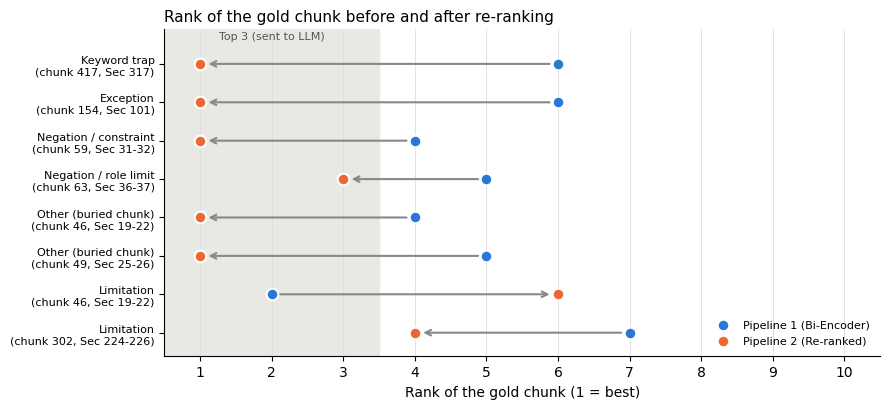

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.2))
labels = [f"{r.category}\n(chunk {r.gold_chunk}, {r.gold_section})" for r in summary.itertuples()]
y = np.arange(len(summary))[::-1]
ax.axvspan(0.5, 3.5, color="#e8e8e4", zorder=0)
ax.text(2, len(summary) - 0.35, "Top 3 (sent to LLM)", ha="center", fontsize=8, color="#555")
for yi, b, r in zip(y, summary["baseline_rank"], summary["reranked_rank"]):
    ax.annotate("", xy=(r, yi), xytext=(b, yi),
                arrowprops=dict(arrowstyle="->", color="#888", lw=1.5, shrinkA=6, shrinkB=6))
ax.scatter(summary["baseline_rank"], y, s=70, color=BLUE, zorder=3, label="Pipeline 1 (Bi-Encoder)", edgecolor="white", linewidth=1.5)
ax.scatter(summary["reranked_rank"], y, s=70, color=ORANGE, zorder=3, label="Pipeline 2 (Re-ranked)", edgecolor="white", linewidth=1.5)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=8)
ax.set_xticks(range(1, 11)); ax.set_xlim(0.5, 10.5); ax.set_ylim(-0.6, len(summary) - 0.1)
ax.set_xlabel("Rank of the gold chunk (1 = best)")
ax.set_title("Rank of the gold chunk before and after re-ranking", fontsize=11, loc="left")
ax.legend(loc="lower right", fontsize=8, frameon=False)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
ax.grid(axis="x", color="#ddd", lw=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("figures/rank_shift.png", dpi=200); plt.show()

In [27]:
# Full Answer 1 vs Answer 2 for every query 
for r in results:
    print(f"[{r['category']}] {r['query']}   (gold rank #{r['baseline_rank']} -> #{r['reranked_rank']})")
    print("  Answer 1 (baseline):", r["answer1"].replace("\n", " "))
    print("  Answer 2 (re-ranked):", r["answer2"].replace("\n", " "))
    print("-" * 110)

[Keyword trap] Is it a crime to buy a stolen mobile phone if I did not know it was stolen?   (gold rank #6 -> #1)
  Answer 1 (baseline): The provided context does not contain this information.
  Answer 2 (re-ranked): Section 317(2) of the Bharatiya Nyaya Sanhita, 2023 provides that a person is punishable for “dishonestly receiving or retaining any stolen property, **knowing or having reason to believe** the same to be stolen.” Because the offence requires knowledge (or reason to believe) that the property is stolen, buying a mobile phone without such knowledge does not constitute a crime under this provision.
--------------------------------------------------------------------------------------------------------------
[Exception] Is it murder if two people get into a sudden quarrel and one kills the other in anger?   (gold rank #6 -> #1)
  Answer 1 (baseline): No. When a killing occurs in the heat of a sudden quarrel, the offender is generally liable only for culpable homicide, not mur

### 6.7 Answer 1 vs. Answer 2: hallucination, omitted clause or misstated rule?

The assignment asks: *did the baseline generate a hallucination, omit an essential clause, or misstate a rule because the critical chunk sat outside the top 3?*

I checked every answer by hand against the gold clause printed above for that query and gave it one label:
* **Correct**: states the rule from the governing clause and cites it.
* **Omitted essential clause**: refuses or answers without the clause that decides the question (e.g. the "except murder" restriction).
* **Misstated rule**: gives a rule that is wrong or based on the wrong clause.
* **Hallucination**: states something that is not in the provided passages at all.

(A refusal like *"The provided context does not contain this information"* is counted as an omission, because the answer is in the Act but did not reach the LLM.)

In [28]:
# My manual judgement of every answer (checked against the gold clause shown for each query).
# Format: query -> (label for Answer 1, label for Answer 2, short reason)
ANSWER_EVAL = {
    "Is it a crime to buy a stolen mobile phone if I did not know it was stolen?":
        ("Omitted essential clause", "Correct",
         "P1 refused: only Sec 303 theft chunks in context. P2 gives Sec 317(2) and the 'knowing or having reason to believe' condition."),
    "Is it murder if two people get into a sudden quarrel and one kills the other in anger?":
        ("Misstated rule", "Correct",
         "P1 reaches 'not murder' but bases it on the provocation rule (Exception 1), which needs grave and sudden provocation. P2 quotes Exception 4 (sudden fight, no premeditation)."),
    "Can a person who commits murder under threat of death escape punishment?":
        ("Omitted essential clause", "Correct",
         "P1 refused: context only had murder definition/punishment. P2 states the Sec 32 restriction: threats do not excuse murder."),
    "When is a person not allowed to use private defence against a public servant?":
        ("Misstated rule", "Misstated rule",
         "Both answers use Explanation 1 and miss Sec 37(1)(a) (no private defence against a public servant acting in good faith when there is no fear of death or grievous hurt). P1 even reverses Explanation 1; P2 treats knowledge alone as the bar."),
    "Is it an offence to harm someone to prevent a bigger harm like a fire?":
        ("Omitted essential clause", "Correct",
         "P1 refused: context was about negligence with fire and intimidation. P2 gives the necessity exception (Sec 19) with the burning-house example."),
    "Is it an offence to hurt someone during a sports match?":
        ("Omitted essential clause", "Correct",
         "P1 refused: context was the hurt / criminal force sections. P2 gives the consent rule of Sec 25 (above 18, fair play)."),
    "Is a ten year old child criminally responsible?":
        ("Correct", "Omitted essential clause",
         "P1 correctly explains Sec 20-21 (7 to 12 years depends on maturity). P2 refused because re-ranking pushed Sec 20-21 out of the Top 3."),
    "Is attempting to commit suicide a crime?":
        ("Omitted essential clause", "Omitted essential clause",
         "Both refused: Sec 226 was not in the Top 3 for either pipeline (rank 7 and rank 4)."),
}

ev = pd.DataFrame([{"category": r["category"], "query": r["query"],
                    "gold in Top 3? (P1 / P2)": f"{'yes' if r['in_top3_baseline'] else 'no'} / {'yes' if r['in_top3_reranked'] else 'no'}",
                    "Answer 1": ANSWER_EVAL[r["query"]][0], "Answer 2": ANSWER_EVAL[r["query"]][1],
                    "reason": ANSWER_EVAL[r["query"]][2]} for r in results])
pd.set_option("display.max_colwidth", 200)
display(ev)
pd.set_option("display.max_colwidth", 120)

,category,query,gold in Top 3? (P1 / P2),Answer 1,Answer 2,reason
0,Keyword trap,Is it a crime to buy a stolen mobile phone if I did not know it was stolen?,no / yes,Omitted essential clause,Correct,P1 refused: only Sec 303 theft chunks in context. P2 gives Sec 317(2) and the 'knowing or having reason to believe' condition.
1,Exception,Is it murder if two people get into a sudden quarrel and one kills the other in anger?,no / yes,Misstated rule,Correct,"P1 reaches 'not murder' but bases it on the provocation rule (Exception 1), which needs grave and sudden provocation. P2 quotes Exception 4 (sudden fight, no premeditation)."
2,Negation / constraint,Can a person who commits murder under threat of death escape punishment?,no / yes,Omitted essential clause,Correct,P1 refused: context only had murder definition/punishment. P2 states the Sec 32 restriction: threats do not excuse murder.
3,Negation / role limit,When is a person not allowed to use private defence against a public servant?,no / yes,Misstated rule,Misstated rule,Both answers use Explanation 1 and miss Sec 37(1)(a) (no private defence against a public servant acting in good faith when there is no fear of death or grievous hurt). P1 even reverses Explanatio...
4,Other (buried chunk),Is it an offence to harm someone to prevent a bigger harm like a fire?,no / yes,Omitted essential clause,Correct,P1 refused: context was about negligence with fire and intimidation. P2 gives the necessity exception (Sec 19) with the burning-house example.
5,Other (buried chunk),Is it an offence to hurt someone during a sports match?,no / yes,Omitted essential clause,Correct,"P1 refused: context was the hurt / criminal force sections. P2 gives the consent rule of Sec 25 (above 18, fair play)."
6,Limitation,Is a ten year old child criminally responsible?,yes / no,Correct,Omitted essential clause,P1 correctly explains Sec 20-21 (7 to 12 years depends on maturity). P2 refused because re-ranking pushed Sec 20-21 out of the Top 3.
7,Limitation,Is attempting to commit suicide a crime?,no / no,Omitted essential clause,Omitted essential clause,Both refused: Sec 226 was not in the Top 3 for either pipeline (rank 7 and rank 4).


In [29]:
# Answer-level metric: how many answers fall in each category, per pipeline
labels_order = ["Correct", "Omitted essential clause", "Misstated rule", "Hallucination"]
counts = pd.DataFrame({"Pipeline 1 (Answer 1)": ev["Answer 1"].value_counts(),
                       "Pipeline 2 (Answer 2)": ev["Answer 2"].value_counts()}).reindex(labels_order).fillna(0).astype(int)
n = len(ev)
counts.loc["Answer accuracy"] = [f"{(ev[col] == 'Correct').sum()}/{n} ({(ev[col] == 'Correct').mean():.1%})" for col in ["Answer 1", "Answer 2"]]
counts

,Pipeline 1 (Answer 1),Pipeline 2 (Answer 2)
Correct,1,5
Omitted essential clause,5,2
Misstated rule,2,1
Hallucination,0,0
Answer accuracy,1/8 (12.5%),5/8 (62.5%)


## 7. Latency Profiling

Each stage is timed separately with `time.perf_counter()`:
* **Baseline retrieval** = encode the query + FAISS search for the Top 10.
* **Re-ranking** = cross-encoder on the 10 (query, chunk) pairs + sorting.
* **LLM generation** = one API call to gpt-oss-120b with 3 chunks (same in both pipelines). It includes network time, so it varies more than the local stages.

The retrieval stages take only milliseconds, and single measurements are noisy, so I repeat them 20 times per query (after a warm-up run) and take the mean. The LLM times are the ones recorded during the runs in Section 6.

In [30]:
queries = [r["query"] for r in results]
N_REPEAT = 20

# warm-up: the first call includes model and thread-pool start-up time
for q in queries:
    rerank(q, baseline_retrieve(q))

rows = []
for q in queries:
    t_base, t_rr = [], []
    for _ in range(N_REPEAT):
        t0 = time.perf_counter(); cands = baseline_retrieve(q); t1 = time.perf_counter()
        rerank(q, cands);                                       t2 = time.perf_counter()
        t_base.append((t1 - t0) * 1000)
        t_rr.append((t2 - t1) * 1000)
    rows.append({"query": q[:55] + "...",
                 "baseline retrieval (ms)": np.mean(t_base),
                 "re-rank step (ms)": np.mean(t_rr)})
lat = pd.DataFrame(rows)
lat["Pipeline 2 retrieval total (ms)"] = lat["baseline retrieval (ms)"] + lat["re-rank step (ms)"]
lat["slow-down factor"] = lat["Pipeline 2 retrieval total (ms)"] / lat["baseline retrieval (ms)"]
lat.loc["MEAN"] = ["(mean over queries)"] + list(lat.iloc[:, 1:].mean())
lat.round(2)

,query,baseline retrieval (ms),re-rank step (ms),Pipeline 2 retrieval total (ms),slow-down factor
0,Is it a crime to buy a stolen mobile phone if I did not...,6.75,234.59,241.34,35.73
1,Is it murder if two people get into a sudden quarrel an...,6.90,222.07,228.97,33.19
2,Can a person who commits murder under threat of death e...,6.47,217.51,223.98,34.60
3,When is a person not allowed to use private defence aga...,5.69,224.35,230.03,40.44
4,Is it an offence to harm someone to prevent a bigger ha...,6.25,231.89,238.13,38.13
5,Is it an offence to hurt someone during a sports match?...,6.03,219.68,225.71,37.42
6,Is a ten year old child criminally responsible?...,5.91,214.96,220.87,37.39
7,Is attempting to commit suicide a crime?...,5.82,203.53,209.36,35.95
MEAN,(mean over queries),6.23,221.07,227.30,36.61


In [31]:
# End-to-end time per query, using the stage times recorded while running the experiments in Section 6.
res = pd.DataFrame(results)
e2e = pd.DataFrame({
    "query": res["query"].str[:55] + "...",
    "P1: retrieval (s)": res["t_retrieve"],
    "P1: LLM (s)": res["t_llm1"],
    "P1 total (s)": res["t_retrieve"] + res["t_llm1"],
    "P2: retrieval + re-rank (s)": res["t_retrieve"] + res["t_rerank"],
    "P2: LLM (s)": res["t_llm2"],
    "P2 total (s)": res["t_retrieve"] + res["t_rerank"] + res["t_llm2"],
})
e2e["re-rank share of P2 (%)"] = 100 * res["t_rerank"] / e2e["P2 total (s)"]
e2e.loc["MEAN"] = ["(mean over queries)"] + list(e2e.iloc[:, 1:].mean())
e2e.round(3)

,query,P1: retrieval (s),P1: LLM (s),P1 total (s),P2: retrieval + re-rank (s),P2: LLM (s),P2 total (s),re-rank share of P2 (%)
0,Is it a crime to buy a stolen mobile phone if I did not...,0.007,3.056,3.064,0.248,1.786,2.033,11.826
1,Is it murder if two people get into a sudden quarrel an...,0.008,1.194,1.202,0.225,1.044,1.269,17.116
2,Can a person who commits murder under threat of death e...,0.007,0.652,0.660,0.225,0.796,1.020,21.310
3,When is a person not allowed to use private defence aga...,0.007,1.207,1.215,0.231,0.998,1.229,18.209
4,Is it an offence to harm someone to prevent a bigger ha...,0.006,0.702,0.708,0.221,0.901,1.122,19.090
5,Is it an offence to hurt someone during a sports match?...,0.007,0.579,0.586,0.223,0.774,0.997,21.680
6,Is a ten year old child criminally responsible?...,0.007,0.998,1.005,0.225,0.849,1.074,20.358
7,Is attempting to commit suicide a crime?...,0.006,0.646,0.652,0.206,0.803,1.010,19.894
MEAN,(mean over queries),0.007,1.130,1.136,0.226,0.994,1.219,18.686


**Summary: baseline retrieval vs. re-ranking pipeline**

The table below summarises the per-query numbers above (mean, median and worst case over the 8 queries).

In [32]:
def stats(x):
    x = np.asarray(x, dtype=float)
    return [x.mean(), np.median(x), x.max()]

per_q = lat.drop(index="MEAN")
res = pd.DataFrame(results)
lat_summary = pd.DataFrame(
    [stats(per_q["baseline retrieval (ms)"]),
     stats(per_q["re-rank step (ms)"]),
     stats(per_q["Pipeline 2 retrieval total (ms)"]),
     stats(1000 * (res["t_retrieve"] + res["t_llm1"])),
     stats(1000 * (res["t_retrieve"] + res["t_rerank"] + res["t_llm2"]))],
    columns=["mean (ms)", "median (ms)", "max (ms)"],
    index=["Pipeline 1: bi-encoder retrieval (Top 10)",
           "Cross-encoder re-ranking of 10 pairs (extra step)",
           "Pipeline 2: retrieval + re-ranking",
           "Pipeline 1 end-to-end (incl. LLM)",
           "Pipeline 2 end-to-end (incl. LLM)"])
lat_summary.round(1)

,mean (ms),median (ms),max (ms)
Pipeline 1: bi-encoder retrieval (Top 10),6.2,6.1,6.9
Cross-encoder re-ranking of 10 pairs (extra step),221.1,220.9,234.6
Pipeline 2: retrieval + re-ranking,227.3,227.3,241.3
Pipeline 1 end-to-end (incl. LLM),1136.4,856.6,3063.6
Pipeline 2 end-to-end (incl. LLM),1219.3,1098.1,2033.3


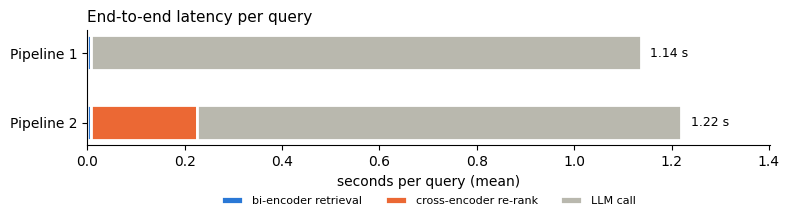

In [33]:
# Stacked bars: where the time goes in each pipeline (mean over the 8 queries)
parts = {"bi-encoder retrieval": [res["t_retrieve"].mean(), res["t_retrieve"].mean()],
         "cross-encoder re-rank": [0, res["t_rerank"].mean()],
         "LLM call": [res["t_llm1"].mean(), res["t_llm2"].mean()]}
colors = {"bi-encoder retrieval": BLUE, "cross-encoder re-rank": ORANGE, "LLM call": "#b9b8ae"}
fig, ax = plt.subplots(figsize=(8, 2.6))
left = np.zeros(2)
for name, vals in parts.items():
    ax.barh([1, 0], vals, left=left, color=colors[name], label=name, height=0.5, edgecolor="white", linewidth=2)
    left += vals
for yi, tot in zip([1, 0], left):
    ax.text(tot + 0.02, yi, f"{tot:.2f} s", va="center", fontsize=9)
ax.set_yticks([1, 0]); ax.set_yticklabels(["Pipeline 1", "Pipeline 2"])
ax.set_xlabel("seconds per query (mean)"); ax.set_xlim(0, left.max() * 1.15)
ax.set_title("End-to-end latency per query", fontsize=11, loc="left")
ax.legend(fontsize=8, frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.35))
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.savefig("figures/latency.png", dpi=200); plt.show()

## 8. Scaling Experiment: Cross-Encoding the Whole Corpus

For the scaling question I measured what happens if the cross-encoder scores **every** chunk for a query instead of only the Top 10, and then extrapolated to larger collections.

The reason this is expensive: a cross-encoder cannot pre-compute anything for the documents. Every new query needs one full transformer forward pass for every (query, chunk) pair. The bi-encoder computes the chunk vectors once offline, and per query it only has to encode the query and do a vector search.

Cross-encoder over all 504 chunks :   13343.6 ms per query
Two-stage (bi-encoder Top 10 + CE)    :     283.2 ms per query
about 26.48 ms per (query, chunk) pair



,corpus size (chunks),CE on all chunks (est. s / query),CE on Top 10 only (est. s / query)
0,504,13.34,0.26
1,10000,264.75,0.26
2,100000,2647.55,0.26
3,1000000,26475.46,0.26


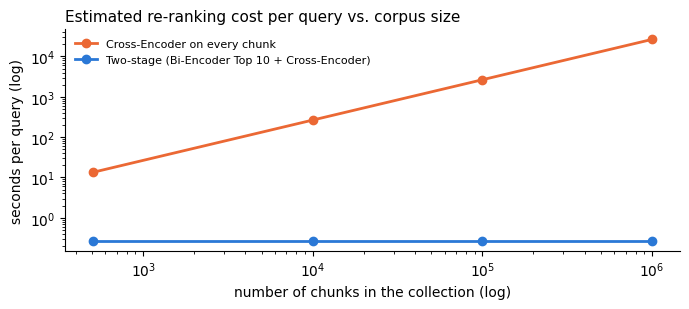

In [34]:
q = queries[0]
pairs_all = [(q, c["text"]) for c in chunks]

t0 = time.perf_counter(); cross_encoder.predict(pairs_all, batch_size=64); t_full = time.perf_counter() - t0
t0 = time.perf_counter(); rerank(q, baseline_retrieve(q));                 t_two  = time.perf_counter() - t0
per_pair = t_full / len(chunks)

print(f"Cross-encoder over all {len(chunks)} chunks : {t_full * 1000:9.1f} ms per query")
print(f"Two-stage (bi-encoder Top 10 + CE)    : {t_two * 1000:9.1f} ms per query")
print(f"about {per_pair * 1000:.2f} ms per (query, chunk) pair\n")

# extrapolation (linear in the number of chunks, same hardware)
scale = pd.DataFrame({"corpus size (chunks)": [len(chunks), 10_000, 100_000, 1_000_000]})
scale["CE on all chunks (est. s / query)"] = scale["corpus size (chunks)"] * per_pair
scale["CE on Top 10 only (est. s / query)"] = TOP_K_RETRIEVE * per_pair
display(scale.round(2))

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(scale["corpus size (chunks)"], scale["CE on all chunks (est. s / query)"], "-o", color=ORANGE, lw=2, label="Cross-Encoder on every chunk")
ax.plot(scale["corpus size (chunks)"], scale["CE on Top 10 only (est. s / query)"], "-o", color=BLUE, lw=2, label="Two-stage (Bi-Encoder Top 10 + Cross-Encoder)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("number of chunks in the collection (log)"); ax.set_ylabel("seconds per query (log)")
ax.set_title("Estimated re-ranking cost per query vs. corpus size", fontsize=11, loc="left")
ax.legend(fontsize=8, frameon=False)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig("figures/scaling.png", dpi=200); plt.show()

In [35]:
# Quality check: would cross-encoding the whole document give a different Top 3 than the two-stage approach?
rows = []
for q in queries:
    full = cross_encoder.predict([(q, c["text"]) for c in chunks], batch_size=64)
    full_top3 = [int(i) for i in np.argsort(-full)[:TOP_K_CONTEXT]]
    two_stage_top3 = [c for c, _, _ in rerank(q, baseline_retrieve(q))[:TOP_K_CONTEXT]]
    rows.append({"query": q[:60] + "...", "full-corpus CE top 3": full_top3,
                 "two-stage top 3": two_stage_top3, "same?": set(full_top3) == set(two_stage_top3)})
pd.DataFrame(rows)

,query,full-corpus CE top 3,two-stage top 3,same?
0,Is it a crime to buy a stolen mobile phone if I did not know...,"[417, 380, 403]","[417, 380, 381]",False
1,Is it murder if two people get into a sudden quarrel and one...,"[154, 152, 149]","[154, 152, 149]",True
2,Can a person who commits murder under threat of death escape...,"[59, 156, 481]","[59, 156, 481]",True
3,When is a person not allowed to use private defence against ...,"[65, 64, 63]","[65, 64, 63]",True
4,Is it an offence to harm someone to prevent a bigger harm li...,"[46, 363, 68]","[46, 363, 68]",True
5,Is it an offence to hurt someone during a sports match?...,"[49, 61, 181]","[49, 61, 181]",True
6,Is a ten year old child criminally responsible?...,"[139, 138, 222]","[139, 138, 76]",False
7,Is attempting to commit suicide a crime?...,"[303, 62, 68]","[155, 160, 154]",False


**Answer to the scaling question.** A cross-encoder has no stored document representation: the score is produced by one forward pass over *(query + chunk)* together, so for every new query all N chunks must be passed through the transformer again. The cost is O(N) transformer passes per query (roughly 25-30 ms each on my CPU), which is already about 13-14 s for this one 504-chunk document and would be hours for a large collection. The bi-encoder computes the chunk vectors once offline and per query only needs one encoding + a vector search, so it is used as a cheap recall filter and the expensive cross-encoder only checks the 10 candidates. The check above shows that for most queries this gives the same Top 3 as cross-encoding everything.

## 9. Short Answers to the Report Questions

These are short notes based on the outputs above; the full answers are in the separate report.

**4.1 Architecture comparison.** The bi-encoder embeds the query and every chunk *separately* and compares the two vectors with cosine similarity, so chunk vectors can be pre-computed and searched quickly, but small words such as "except" or "not" hardly change a vector. The cross-encoder reads *(query, chunk)* as one input, so self-attention connects every query token with every chunk token and the score reflects whether this chunk answers this question. It is much more precise, but nothing can be pre-computed.

**4.2 Rank shifts and answers.** (Section 6.6 and 6.7)
* On the six main failure queries the gold chunk was at rank 4-6 for the bi-encoder and was moved to rank 1 (five queries) or rank 3 (one query) by the cross-encoder, e.g. *Chunk 417 moved from Rank #6 to Rank #1* for the stolen-phone keyword trap.
* Hit@3 went from 0.125 to 0.75, Hit@1 from 0 to 0.625 and MRR@10 from 0.24 to 0.72 over the 8 queries.
* Answer 1 mostly **omitted the essential clause** (5 of 8, the LLM refused because the clause was not in the context) or **misstated the rule** (2 of 8). I did not see a clear hallucination: with temperature 0 and the strict prompt the LLM refused rather than invent a law. Answer 2 was correct for 5 of 8 queries.
* Re-ranking is not perfect: for the 10-year-old child query it pushed the correct chunk out of the Top 3 and turned a correct answer into a refusal, and for the private defence query the gold chunk reached the prompt but the LLM still misread the negation.

**4.3 Latency.** (Section 7) Bi-encoder retrieval takes a few milliseconds per query, while re-ranking 10 pairs adds about 0.2 s on my CPU, so the retrieval stage is roughly 30x slower. End to end, the LLM call (about 1 s) is still the largest part.

**4.4 Scaling.** (Section 8) A cross-encoder has to run one transformer pass for every (query, chunk) pair at query time. For this single document that is already 13-14 s per query, and it grows linearly with the collection. Using the bi-encoder as a fast filter and the cross-encoder only on 10 candidates gives the same Top 3 as full cross-encoding for 5 of the 8 queries at around 2% of the cost.